## ANN (Artifical Neural Networks)

In [37]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

In [38]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [39]:
data = load_breast_cancer()
x = data.data
y = data.target

x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)


In [40]:
model = Sequential()
model.add(Dense(16, activation='relu', input_shape=(30,))) # input layer
model.add(Dense(8, activation='relu')) # hidden layer
model.add(Dense(1, activation='sigmoid')) # output layer

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()



Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

In [41]:
from tensorflow.keras.callbacks import Callback

class WeightLogger(Callback):
    def on_epoch_end(self, epoch, logs = None):
        print(f'Epoch No.{epoch+1}')
        for i, layer in enumerate(self.model.layers):
            print(f'Layer No. {i+1}')
            w,b = layer.get_weights()
            print('Weights:', w)
            print('Bias:', b)

In [42]:
history = model.fit(x_train, y_train, batch_size=16, epochs=20, verbose=1, validation_split=0.2)
# add callbacks=[WeightLogger()] above to see the weights & bias of each layer
# if u keep increasing the epochs, better accuracy will come. But it's best to increase for complex data like images

y_pred_proba = model.predict(x_test)
y_pred = (y_pred_proba>0.5).astype(int).flatten()
print('Accuracy Score:', accuracy_score(y_test, y_pred))

Epoch 1/20


23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - accuracy: 0.5577 - loss: 0.6708 - val_accuracy: 0.7692 - val_loss: 0.5740
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9093 - loss: 0.5123 - val_accuracy: 0.9231 - val_loss: 0.4659
Epoch 3/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9286 - loss: 0.4144 - val_accuracy: 0.9231 - val_loss: 0.3689
Epoch 4/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9423 - loss: 0.3207 - val_accuracy: 0.9231 - val_loss: 0.2814
Epoch 5/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9423 - loss: 0.2382 - val_accuracy: 0.9341 - val_loss: 0.2176
Epoch 6/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9615 - loss: 0.1802 - val_accuracy: 0.9341 - val_loss: 0.1774
Epoch 7/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9670 - loss: 0.1438 - val_accuracy: 0.9451 - val_loss: 0.1507
Epoch 8/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9725 - loss: 0.1206 - val_accuracy: 0.9451 - val_loss: 0.1311
Ep

In [43]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

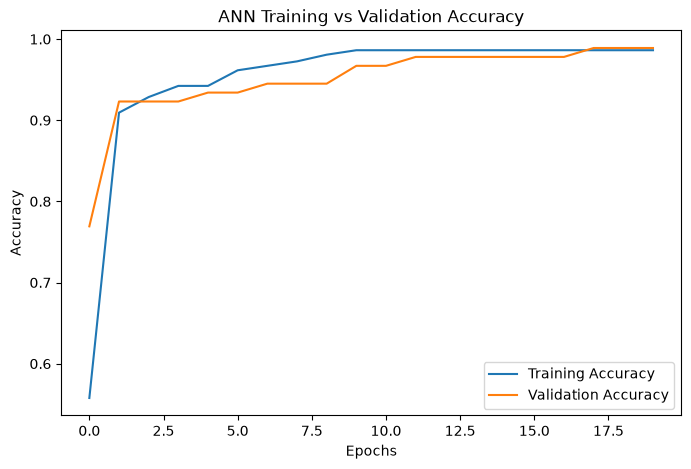

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('ANN Training vs Validation Accuracy')
plt.legend()
plt.show()

After a certain No. of epochs, the Accuracy converges

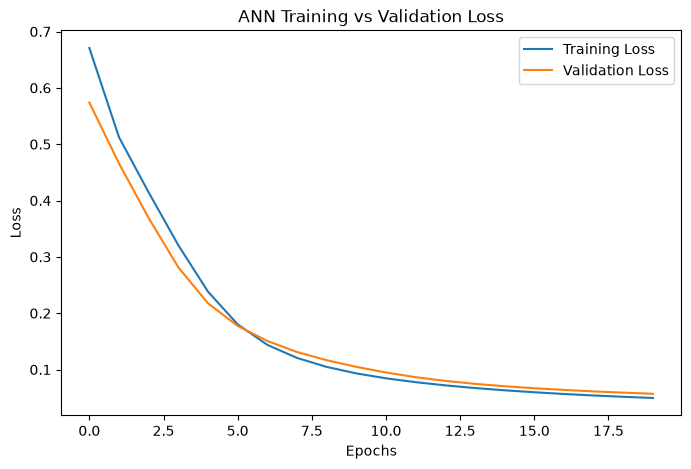

In [45]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('ANN Training vs Validation Loss')
plt.legend()
plt.show()